# EDA: NYC permitted events & holidays

Sources (relative to the repo root; the notebook is run from `notebooks/`):
- `data/NYC_Permitted_Event_Information_-_Historical_20260927.csv`
- `data/us_federal_holidays_2016_2017.csv`
- `data/nyc_calendar_days_2016_2017.csv` (hand-built NYC calendar days)

Goal: surface data-quality issues that drive the silver/gold design.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)
sns.set_theme(style="whitegrid")
DATA = "../data/"
FMT = "%m/%d/%Y %I:%M:%S %p"
ev = pd.read_csv(DATA + "NYC_Permitted_Event_Information_-_Historical_20260927.csv", dtype=str)
ev.shape

(425429, 13)

## 1. Events: structure and missing values

In [2]:
ev.head()

,Event ID,Event Name,Start Date/Time,End Date/Time,Event Agency,Event Type,Event Borough,Event Location,Event Street Side,Street Closure Type,Community Board,Police Precinct,CEMSID
0,257309,GrowNYC's Governors Island Teaching Garden,01/01/2016 12:00:00 AM,12/15/2016 12:00:00 AM,Trust for Governor's Island,Public Program / Exhibitions,Manhattan,NaN,NaN,NaN,NaN,NaN,"0,"
1,259378,Permitted Film Event,01/01/2016 12:00:00 AM,06/30/2016 09:00:00 AM,Mayor's Office of Media & Entertainment,Theater Load in and Load Outs,Manhattan,WEST 44 STREET between BROADWAY and 6 AVENUE,NaN,NaN,"5,","14,",NaN
2,260142,Permitted Film Event,01/01/2016 12:00:00 AM,01/31/2016 12:00:00 AM,Mayor's Office of Media & Entertainment,Shooting Permit,Manhattan,"310 WEST 35 STREET between 8 AVENUE and 9 AVENUE, WES...",NaN,NaN,"4,","14,",NaN
3,242474,New Year's Eve,01/01/2016 12:00:00 AM,01/01/2016 11:59:00 PM,Parks Department,Special Event,Manhattan,Father Duffy Square: Father Duffy Square,NaN,NaN,"5,","18,","241,"
4,244568,Big Apple Circus,01/01/2016 12:00:00 AM,01/01/2016 11:59:00 PM,Parks Department,Special Event,Manhattan,"Damrosch Park: Damrosch Park ,Damrosch Park: Tent Area",NaN,NaN,"7,","20,","233, 232,"


In [3]:
pd.DataFrame({"nulls": ev.isna().sum(), "null_pct": (ev.isna().mean() * 100).round(2), "nunique": ev.nunique()})

,nulls,null_pct,nunique
Event ID,0,0.00,59761
Event Name,0,0.00,20741
Start Date/Time,0,0.00,22187
End Date/Time,0,0.00,21785
Event Agency,0,0.00,6
Event Type,0,0.00,33
Event Borough,83,0.02,5
Event Location,90,0.02,18197
Event Street Side,407470,95.78,6
Street Closure Type,406925,95.65,7


In [4]:
ev["start"] = pd.to_datetime(ev["Start Date/Time"], format=FMT)
ev["end"] = pd.to_datetime(ev["End Date/Time"], format=FMT)
ev["duration_h"] = (ev["end"] - ev["start"]).dt.total_seconds() / 3600
print("unparseable timestamps:", ev[["start", "end"]].isna().sum().to_dict())
print("range:", ev.start.min(), "->", ev.start.max())
print("rows starting in 2018 (outside project window):", (ev.start.dt.year == 2018).sum())

unparseable timestamps: {'start': 0, 'end': 0}
range: 2016-01-01 00:00:00 -> 2018-01-01 00:00:00
rows starting in 2018 (outside project window): 4


## 2. Keys and duplicates

`Event ID` repeats (one row per date/location), so it is not a row key.

In [5]:
print("rows:", len(ev), "| unique Event IDs:", ev["Event ID"].nunique())
key = ["Event ID", "Start Date/Time", "End Date/Time", "Event Location"]
print("duplicate rows on composite key:", ev.duplicated(key).sum())
print("IDs with >1 name:", (ev.groupby("Event ID")["Event Name"].nunique() > 1).sum(),
      "| >1 type:", (ev.groupby("Event ID")["Event Type"].nunique() > 1).sum())
ev.groupby("Event ID").size().describe()

rows: 425429 | unique Event IDs: 59761
duplicate rows on composite key: 0


IDs with >1 name: 0 | >1 type: 0


count    59761.000000
mean         7.118840
std         18.037213
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        365.000000
dtype: float64

## 3. Invalid and extreme time ranges

In [6]:
bad = ev[ev.end < ev.start]
print("end before start:", len(bad))
bad[["Event ID", "Event Name", "Start Date/Time", "End Date/Time", "Event Type"]].head(8)

end before start: 308


,Event ID,Event Name,Start Date/Time,End Date/Time,Event Type
61,247190,New Year's Eve Celebration & Fireworks,01/01/2016 11:00:00 PM,01/01/2016 01:00:00 AM,Special Event
45074,280950,Soccer -Regulation,05/08/2016 08:00:00 AM,05/08/2016 12:00:00 AM,Sport - Youth
49544,276759,Audi Bold Notion,05/12/2016 06:00:00 PM,05/12/2016 05:00:00 PM,Production Event
50545,285743,Movies Under the Stars,05/13/2016 07:00:00 PM,05/13/2016 12:00:00 AM,Special Event
50901,280950,Soccer -Regulation,05/14/2016 08:00:00 AM,05/14/2016 12:00:00 AM,Sport - Youth
51723,276759,Audi Bold Notion,05/14/2016 06:00:00 PM,05/14/2016 05:00:00 PM,Production Event
52058,280950,Soccer -Regulation,05/15/2016 08:00:00 AM,05/15/2016 12:00:00 AM,Sport - Youth
58056,280950,Soccer -Regulation,05/21/2016 08:00:00 AM,05/21/2016 12:00:00 AM,Sport - Youth


{0.5: 5.0, 0.9: 12.0, 0.99: 16.5, 0.999: 496.4, 1.0: 29551.0}


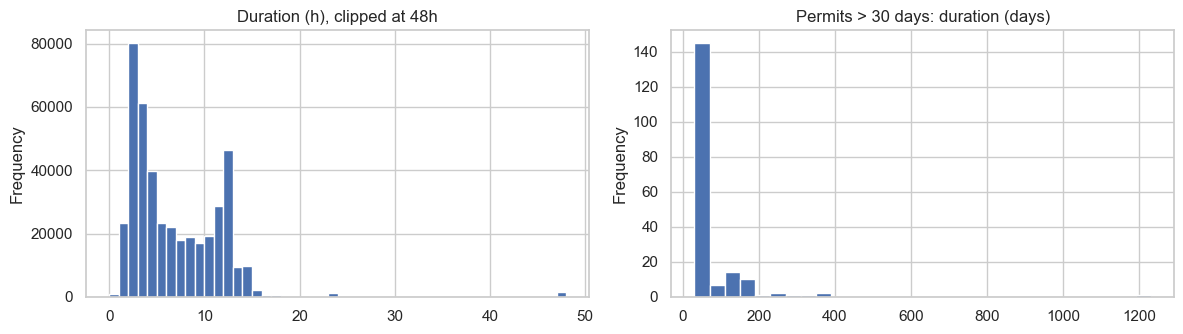

In [7]:
valid = ev[ev.end >= ev.start]
print(valid.duration_h.quantile([.5, .9, .99, .999, 1]).round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
valid.duration_h.clip(upper=48).plot.hist(bins=48, ax=ax[0]); ax[0].set_title("Duration (h), clipped at 48h")
valid[valid.duration_h > 720].duration_h.div(24).plot.hist(bins=30, ax=ax[1]); ax[1].set_title("Permits > 30 days: duration (days)")
plt.tight_layout()

In [8]:
multi = valid[valid.end.dt.normalize() > valid.start.dt.normalize()]
print("multi-day permits:", len(multi), "| longer than 30 days:", (valid.duration_h > 720).sum())
multi["Event Type"].value_counts().head(10)

multi-day permits: 1818 | longer than 30 days: 184


Event Type
Production Event                 562
Theater Load in and Load Outs    377
Religious Event                  198
Special Event                    144
Street Event                     130
Plaza Event                       89
Sidewalk Sale                     74
Street Festival                   55
Mobile Unit                       50
Shooting Permit                   49
Name: count, dtype: int64

In [9]:
valid.sort_values("duration_h", ascending=False)[["Event Name", "Start Date/Time", "End Date/Time", "Event Type", "duration_h"]].head(6)

,Event Name,Start Date/Time,End Date/Time,Event Type,duration_h
51163,play:ground,05/14/2016 10:00:00 AM,09/27/2019 05:00:00 PM,Public Program / Exhibitions,29551.0
109,Hell's Kitchen Flea Market,01/02/2016 09:00:00 AM,12/31/2016 04:00:00 PM,Street Festival,8743.0
208606,Hells Kitchen Flea Market,01/01/2017 09:30:00 AM,12/31/2017 04:00:00 PM,Street Festival,8742.5
0,GrowNYC's Governors Island Teaching Garden,01/01/2016 12:00:00 AM,12/15/2016 12:00:00 AM,Public Program / Exhibitions,8376.0
218698,Mobile Medical Unit,03/23/2017 01:00:00 PM,12/21/2017 05:00:00 PM,Street Event,6556.0
216063,Stone Street Pedestrian Mall,03/17/2017 11:00:00 AM,11/30/2017 10:00:00 PM,Street Event,6203.0


## 4. Event mix: sports dominate

sports share: 0.795


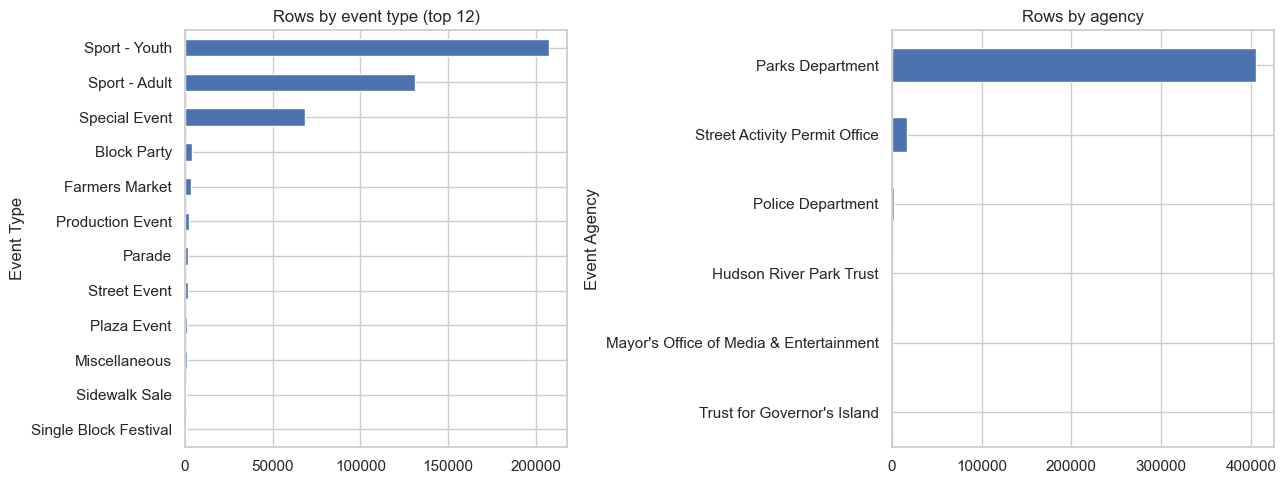

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ev["Event Type"].value_counts().head(12).sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Rows by event type (top 12)")
ev["Event Agency"].value_counts().sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Rows by agency")
plt.tight_layout()
print("sports share:", ev["Event Type"].str.startswith("Sport").mean().round(3))

<Axes: title={'center': 'Events per month (by start date)'}, xlabel='month'>

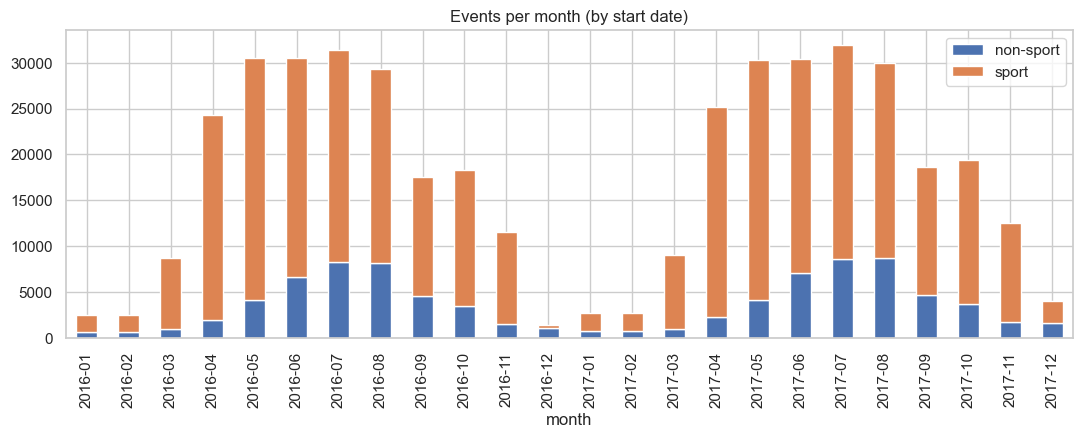

In [11]:
ev["is_sport"] = ev["Event Type"].str.startswith("Sport")
ev["month"] = ev.start.dt.to_period("M")
m = ev[ev.start.dt.year < 2018].groupby(["month", "is_sport"]).size().unstack(fill_value=0)
m.columns = ["non-sport", "sport"]
m.plot.bar(stacked=True, figsize=(13, 4), title="Events per month (by start date)")

## 5. Daily volume and weekday pattern

days with zero events: 0 | min: 17 | max: 1500 on 2017-08-19


<Axes: title={'center': 'Events starting per day'}>

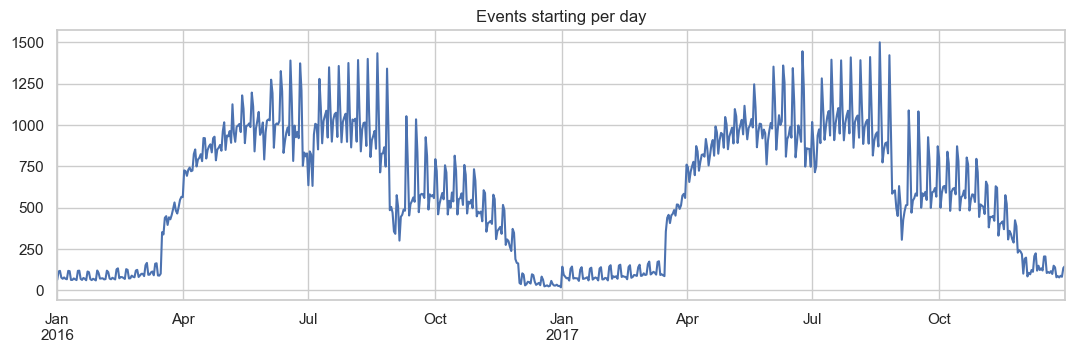

In [12]:
days = pd.date_range("2016-01-01", "2017-12-31")
daily = ev[ev.start.dt.year < 2018].groupby(ev.start.dt.normalize()).size().reindex(days, fill_value=0)
print("days with zero events:", (daily == 0).sum(), "| min:", daily.min(), "| max:", daily.max(), "on", daily.idxmax().date())
daily.plot(figsize=(13, 3.5), title="Events starting per day")

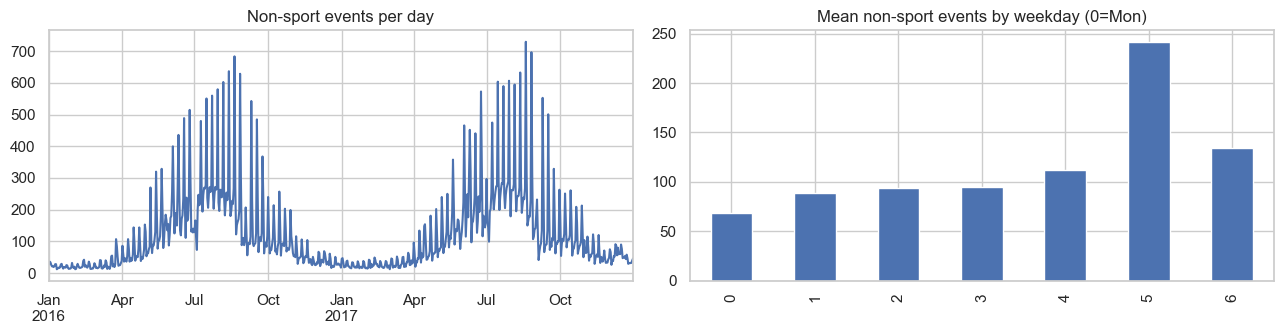

In [13]:
nonsport = ev[(~ev.is_sport) & (ev.start.dt.year < 2018)]
dn = nonsport.groupby(nonsport.start.dt.normalize()).size().reindex(days, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
dn.plot(ax=ax[0], title="Non-sport events per day")
dn.groupby(dn.index.dayofweek).mean().plot.bar(ax=ax[1], title="Mean non-sport events by weekday (0=Mon)")
plt.tight_layout()

## 6. High-impact event types (candidate gold features)

<Axes: title={'center': 'High-impact events per month'}, xlabel='start'>

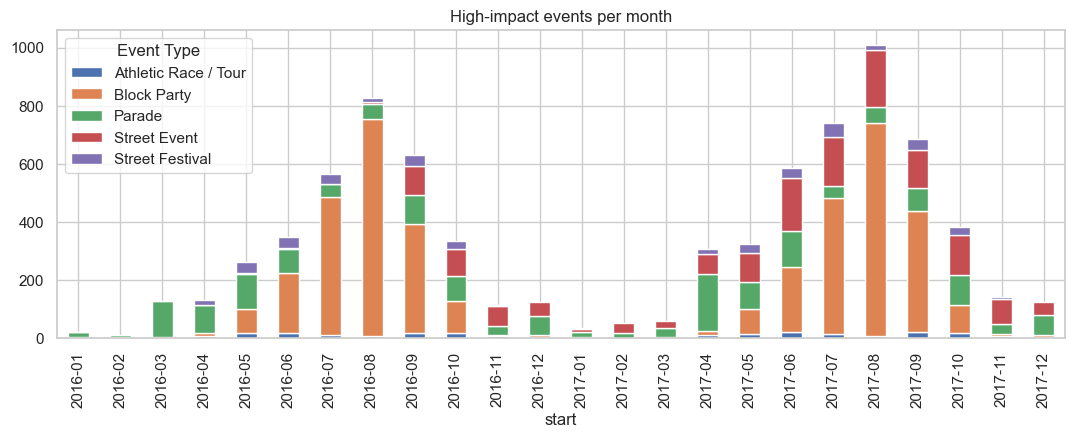

In [14]:
impact = ["Parade", "Athletic Race / Tour", "Street Festival", "Street Event", "Block Party"]
x = ev[ev["Event Type"].isin(impact) & (ev.start.dt.year < 2018)]
x.groupby([x.start.dt.to_period("M"), "Event Type"]).size().unstack(fill_value=0).plot.bar(stacked=True, figsize=(13, 4), title="High-impact events per month")

In [15]:
for kw in ["Marathon", "Pride", "Halloween", "New Year", "Macy", "Thanksgiving", "St. Patrick", "Puerto Rican"]:
    mm = ev[ev["Event Name"].str.contains(kw, case=False, na=False)]
    print(f"{kw:15s} rows={len(mm):4d} distinct days={mm.start.dt.date.nunique()}")

Marathon        rows= 182 distinct days=122
Pride           rows=  69 distinct days=41
Halloween       rows= 196 distinct days=26


New Year        rows=  69 distinct days=51
Macy            rows=  52 distinct days=43
Thanksgiving    rows=  37 distinct days=23


St. Patrick     rows=  14 distinct days=13
Puerto Rican    rows=  22 distinct days=10


## 7. Location and categorical hygiene

In [16]:
print(ev["Event Borough"].value_counts(dropna=False).to_dict())
print("missing borough:", ev["Event Borough"].isna().sum(), "| missing location:", ev["Event Location"].isna().sum())
print(ev[ev["Event Borough"].isna()]["Event Type"].value_counts().head(5).to_dict())
ev[ev["Event Borough"].isna() & (ev["Event Agency"] == "Police Department")][["Event Name", "Event Type", "Start Date/Time"]].head()

{'Manhattan': 170002, 'Brooklyn': 108162, 'Queens': 78506, 'Bronx': 51103, 'Staten Island': 17573, nan: 83}
missing borough: 83 | missing location: 90
{'Sport - Adult': 79, 'Parade': 2, 'Special Event': 2}


,Event Name,Event Type,Start Date/Time
10467,Good friday Procession,Parade,03/25/2016 03:30:00 PM
26564,Walk Armenia,Parade,04/17/2016 01:00:00 PM


In [17]:
for c in ["Event Name", "Event Type", "Event Borough", "Event Agency", "Event Location"]:
    s = ev[c].dropna()
    print(f"{c:15s} untrimmed={(s != s.str.strip()).sum()} N/A={(s.str.upper().str.strip() == 'N/A').sum()}")
for c in ["Street Closure Type", "Event Street Side", "Community Board", "Police Precinct", "CEMSID"]:
    print(f"{c:20s} null={ev[c].isna().sum():6d} N/A={(ev[c].str.upper().str.strip() == 'N/A').sum():6d}")
ev["Community Board"].dropna().sample(6, random_state=1).tolist(), ev["CEMSID"].dropna().sample(6, random_state=1).tolist()

Event Name      untrimmed=0 N/A=0


Event Type      untrimmed=0 N/A=0


Event Borough   untrimmed=0 N/A=0


Event Agency    untrimmed=0 N/A=0


Event Location  untrimmed=0 N/A=0


Street Closure Type  null=406925 N/A=     0
Event Street Side    null=407470 N/A=     0
Community Board      null=    88 N/A=     0


Police Precinct      null=    88 N/A=     0


CEMSID               null= 16209 N/A=     0


(['07,', '11,', '03,', '09,', '07,', '11,'],
 ['7853,', '5790,', '5496,', '10179,', '9588, 9589,', '8138,'])

## 8. Holidays: federal and NYC calendar

In [18]:
fed = pd.read_csv(DATA + "us_federal_holidays_2016_2017.csv").assign(category="federal")
nyc = pd.read_csv(DATA + "nyc_calendar_days_2016_2017.csv").assign(category="nyc_calendar")
hol = pd.concat([fed, nyc], ignore_index=True)
hol["date"] = pd.to_datetime(hol.date); hol["observed_date"] = pd.to_datetime(hol.observed_date)
print("rows:", len(hol), "| duplicates:", hol.duplicated(["date", "holiday_name"]).sum())
print("weekday mismatches:", (hol.date.dt.day_name() != hol.weekday).sum())
print("observed != date:")
display(hol[hol.date != hol.observed_date][["holiday_name", "date", "weekday", "observed_date"]])
hol.groupby(["year", "category"]).size().unstack()

rows: 40 | duplicates: 0
weekday mismatches: 0
observed != date:


,holiday_name,date,weekday,observed_date
9,Christmas Day,2016-12-25,Sunday,2016-12-26
10,New Year's Day,2017-01-01,Sunday,2017-01-02
17,Veterans Day,2017-11-11,Saturday,2017-11-10


category,federal,nyc_calendar
year,,
2016,10,10
2017,10,10


In [19]:
print("dates with two holiday rows:", hol.groupby("date").size().gt(1).sum())
hol.sort_values("date")[["date", "weekday", "holiday_name", "category"]].reset_index(drop=True)

dates with two holiday rows: 0


,date,weekday,holiday_name,category
0,2016-01-01,Friday,New Year's Day,federal
1,2016-01-18,Monday,Martin Luther King Jr. Day,federal
2,2016-02-15,Monday,Washington's Birthday (Presidents Day),federal
3,2016-03-17,Thursday,St. Patrick's Day,nyc_calendar
4,2016-03-27,Sunday,Easter Sunday,nyc_calendar
5,2016-05-08,Sunday,Mother's Day,nyc_calendar
6,2016-05-30,Monday,Memorial Day,federal
7,2016-06-12,Sunday,Puerto Rican Day Parade,nyc_calendar
8,2016-06-26,Sunday,NYC Pride March,nyc_calendar
9,2016-07-04,Monday,Independence Day,federal


## 9. Holidays vs event activity

Does event volume move on holidays? (Informs whether event features add signal beyond the holiday flag.)

In [20]:
allh = set(hol.date) | set(hol.observed_date)
d = pd.DataFrame({"events": daily, "non_sport": dn})
d["is_holiday"] = d.index.isin(allh)
d["weekend"] = d.index.dayofweek >= 5
print(d.groupby(["weekend", "is_holiday"])[["events", "non_sport"]].mean().round(1))
top = hol.set_index("date").holiday_name.to_dict()
tbl = d[d.is_holiday].assign(name=lambda t: t.index.map(top))[["name", "events", "non_sport"]]
tbl.sort_values("non_sport", ascending=False).head(10)

                    events  non_sport
weekend is_holiday                   
False   False        543.8       93.8
        True         331.2       49.3
True    False        710.0      193.4
        True         622.3      123.4


,name,events,non_sport
2017-06-25,NYC Pride March,1221,331
2017-06-11,Puerto Rican Day Parade,1257,321
2016-06-26,NYC Pride March,1209,292
2016-06-12,Puerto Rican Day Parade,1203,252
2017-05-14,Mother's Day,1009,134
2017-11-11,Veterans Day,629,122
2017-10-31,Halloween,519,104
2016-05-08,Mother's Day,954,104
2017-07-04,Independence Day,751,99
2017-04-16,Easter Sunday,859,95


## Findings

1. **Multi-day permits**: ~1.8k valid permits span several days and ~180 run longer than 30 days (one ends in 2019). Bronze partitions by start date, so Gold must expand them across days and exclude or cap long-running permits (`is_long_running` flag in silver).
2. **Sports dominate** (~80% of rows) and follow the season; raw daily event counts mostly measure the sports calendar. Gold should split counts by type and keep high-impact types separate.
3. **Invalid ranges**: ~300 rows end before they start; flagged (`is_valid_time_range`), not dropped.
4. **Missing location**: ~80-90 rows lack borough/location (mostly adult soccer, a few Police parades); kept with nulls.
5. **Placeholders**: `N/A` strings and trailing commas in ID lists are cleaned in silver; `event_id` repeats so silver adds `event_row_key`.
6. **Holidays** are clean; the federal list misses NYC-specific days, so the NYC calendar file adds NYE, Halloween, Marathon, Pride, etc. with `holiday_category`.